## Упражнение

- Загрузите и нанесите на график исторические цены закрытия Tesla (``TSLA``) и Equinor (``EQNR``) за годы ``2019-12-31``- ``2022-12-31``.
- Для каждого временного ряда:
    - Проверьте, выглядит ли временной ряд стационарным.
    - Вычислите коэффициент Херста для обоих временных рядов.
    - В какие акции вы хотели бы инвестировать? Обоснуйте свой ответ на основе тестов и значения $H$.
    - Смоделируйте цены акций с помощью GBM.

- Какая симуляция кажется более надежной? Для Tesla или Equinor?
- Чтобы обосновать свой ответ:
1. вычислите симуляцию не менее 100 раз.
2. Вычислите MSE между истинными ценами акций и смоделированными.
3. Сравните ожидаемое значение MAPE для двух акций.

In [1]:
import warnings
warnings.simplefilter(action="ignore", category=(FutureWarning, DeprecationWarning))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller
import yfinance as yf
np.random.seed(0)  # For reproducible results

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
tesla_dataset = "/content/drive/MyDrive/MAGA/regression/KT-1/tesla.csv"
eqnr_dataset = "/content/drive/MyDrive/MAGA/regression/KT-1/eqnr.csv"

tesla = pd.read_csv(tesla_dataset)
eqnr = pd.read_csv(eqnr_dataset)

print('Данные Tesla:')
print(tesla.head())
print('\n\nДанные Equinor:')
print(eqnr.head())

Данные Tesla:
           Date   Open   High    Low  Close
0  Dec 31, 2019  27.00  28.09  26.81  27.89
1   Jan 2, 2020  28.30  28.71  28.11  28.68
2   Jan 3, 2020  29.37  30.27  29.13  29.53
3   Jan 6, 2020  29.36  30.10  29.33  30.10
4   Jan 7, 2020  30.76  31.44  30.22  31.27


Данные Equinor:
           Date   Open   High    Low  Close
0  Dec 31, 2019  19.72  19.91  19.70  19.91
1   Jan 2, 2020  20.27  20.43  20.16  20.43
2   Jan 3, 2020  20.59  20.64  20.39  20.49
3   Jan 6, 2020  20.90  21.04  20.88  20.96
4   Jan 7, 2020  20.68  20.74  20.54  20.72


In [5]:
def hurst(ts):
  lags = range(2, 100)
  tau = [np.var(np.subtract(ts[lag:], ts[:-lag])) for lag in lags]
  poly = np.polyfit(np.log(lags), np.log(tau), 1)
  return poly[0]/2.0

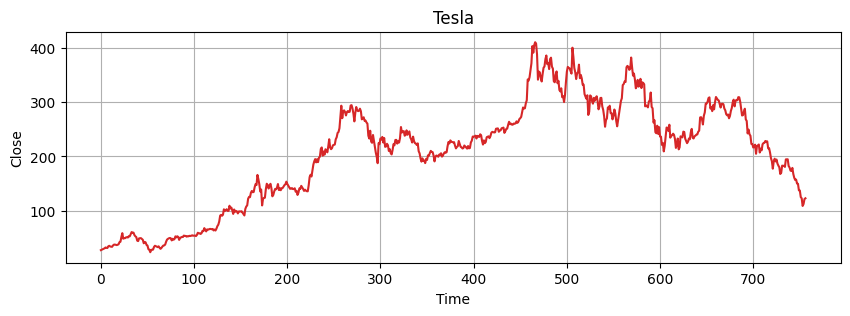

In [6]:
time_tesla = np.arange(len(tesla))

fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(time_tesla, tesla['Close'], color='tab:red')
ax.set_xlabel("Time")
ax.set_ylabel("Close")
plt.title("Tesla");
plt.grid()

In [7]:
# проверка стационарности: ADF-тест
adf_result = adfuller(tesla['Close'])
print("Результаты ADF-теста на стационарность")
print(f"ADF-статистика: {adf_result[0]:.4f}")
print(f"p-value:       {adf_result[1]:.4f}")
print(f"Критические значения:")
for key, value in adf_result[4].items():
  print(f"   {key}: {value:.4f}")

# интерпретация
if adf_result[1] <= 0.05:
  print("\n→ Ряд СТАЦИОНАРЕН (нулевая гипотеза отвергнута)")
else:
  print("\n→ Ряд НЕСТАЦИОНАРЕН (нулевая гипотеза принимается)")

Результаты ADF-теста на стационарность
ADF-статистика: -1.8638
p-value:       0.3493
Критические значения:
   1%: -3.4391
   5%: -2.8654
   10%: -2.5688

→ Ряд НЕСТАЦИОНАРЕН (нулевая гипотеза принимается)


Ряд не выглядит стационарным, p-value это подтверждает.

In [8]:
hurst_tesla = hurst(tesla['Close'].values)
print(f"Hurst Tesla: {hurst_tesla:.4f}")

Hurst Tesla: 0.4626


Акции Tesla ближе к случайному блужданию. С точки зрения инвестирования, в движениях цен нет автокорреляций, будущие значения нельзя предсказать на основе прошлых.

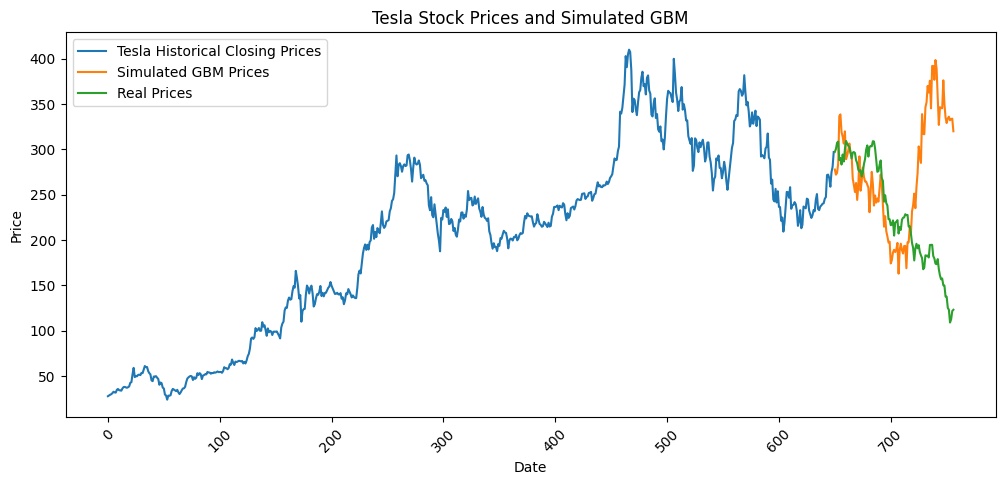

In [11]:
data2 = tesla[:650]
data3 = tesla[650:]
test_days = len(data3)

returns = data2['Close'].pct_change()

mu = returns.mean() * 252  # Annualize the mean
sigma = returns.std() * np.sqrt(252)  # Annualize the std deviation

T = 1  # Time horizon in years
dt = 1/test_days  # Time step in years, assuming 252 trading days per year
N = int(T/dt)  # Number of time steps
time_step = np.linspace(0, T, N)
S0 = data2['Close'].iloc[-1]  # Starting stock price (latest close price)

W = np.random.standard_normal(size=N)
W = np.cumsum(W)*np.sqrt(dt)  # Cumulative sum for the Wiener process
X = (mu - 0.5 * sigma**2) * time_step + sigma * W
S = S0 * np.exp(X)  # GBM formula

plt.figure(figsize=(12, 5))
plt.plot(data2['Close'], label='Tesla Historical Closing Prices')
plt.plot(data3.index, S, label='Simulated GBM Prices')
plt.plot(data3['Close'], label='Real Prices')
plt.legend()
plt.title('Tesla Stock Prices and Simulated GBM')
plt.xlabel('Date')
plt.ylabel('Price')
plt.xticks(rotation=45);

In [12]:
n_paths = 10
paths = []
for _ in range(n_paths):
  W = np.cumsum(np.random.standard_normal(size=N))*np.sqrt(dt)
  X = (mu - 0.5 * sigma**2) * time_step + sigma * W
  paths.append(S0 * np.exp(X))

path_mean = np.array(paths).mean(axis=0)
path_std = np.array(paths).std(axis=0)

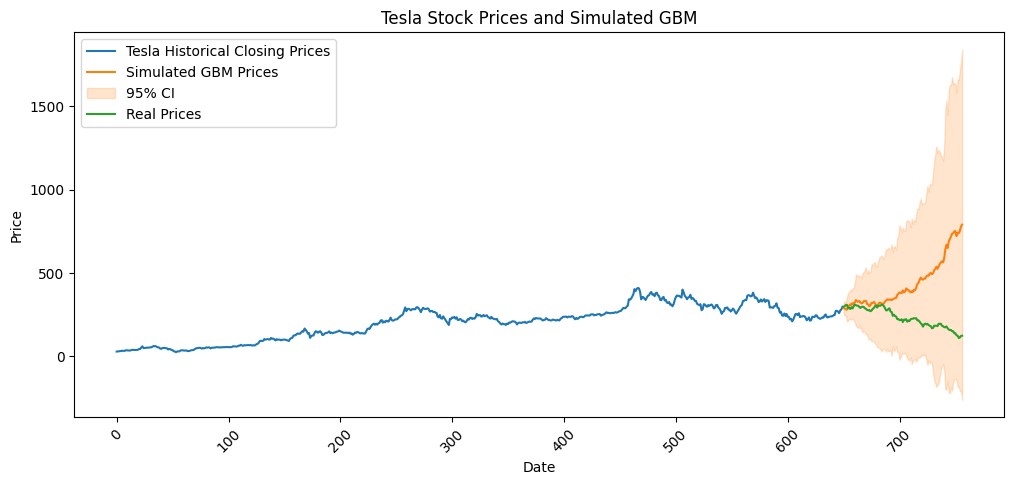

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(data2['Close'], label='Tesla Historical Closing Prices')
plt.plot(data3.index, path_mean, label='Simulated GBM Prices')
plt.fill_between(data3.index, path_mean-1.96*path_std, path_mean+1.96*path_std, color='tab:orange', alpha=0.2, label='95% CI')
plt.plot(data3['Close'], label='Real Prices')
plt.legend(loc='upper left')
plt.title('Tesla Stock Prices and Simulated GBM')
plt.xlabel('Date')
plt.ylabel('Price')
plt.xticks(rotation=45);

Как и было предположено, акции Tesla сложно предсказать. На графике видно, что прогноз и тест сильно различаются.

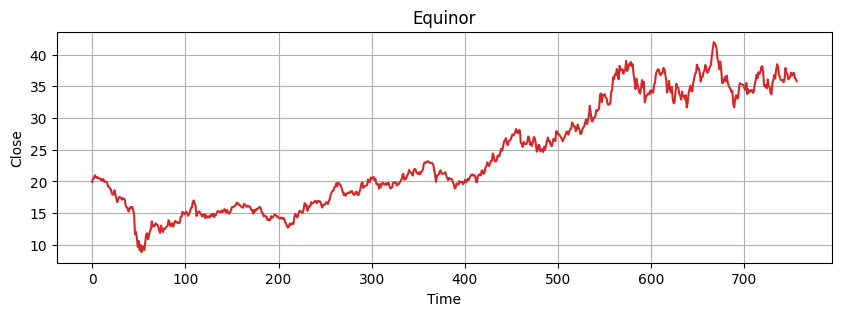

In [14]:
time_eqnr = np.arange(len(eqnr))

fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(time_eqnr, eqnr['Close'], color='tab:red')
ax.set_xlabel("Time")
ax.set_ylabel("Close")
plt.title("Equinor");
plt.grid()

In [15]:
# проверка стационарности: ADF-тест
adf_result = adfuller(eqnr['Close'])
print("Результаты ADF-теста на стационарность")
print(f"ADF-статистика: {adf_result[0]:.4f}")
print(f"p-value:       {adf_result[1]:.4f}")
print(f"Критические значения:")
for key, value in adf_result[4].items():
  print(f"   {key}: {value:.4f}")

# интерпретация
if adf_result[1] <= 0.05:
  print("\n→ Ряд СТАЦИОНАРЕН (нулевая гипотеза отвергнута)")
else:
  print("\n→ Ряд НЕСТАЦИОНАРЕН (нулевая гипотеза принимается)")

Результаты ADF-теста на стационарность
ADF-статистика: -0.5853
p-value:       0.8743
Критические значения:
   1%: -3.4390
   5%: -2.8654
   10%: -2.5688

→ Ряд НЕСТАЦИОНАРЕН (нулевая гипотеза принимается)


Ряд не выглядит стационарным, p-value это подтверждает.

In [16]:
hurst_eqnr = hurst(eqnr['Close'].values)
print(f"Hurst Equinor: {hurst_eqnr:.4f}")

Hurst Equinor: 0.3396


Акции Equinor находятся между случайным блужданием и возвратом к среднему. Цена акций может иметь тенденцию возвращаться к своему историческому среднему значению. Данный актив менее рискован в долгосрочной перспективе. Предпочтительнее инвестировать в Equinor, чем в Tesla.

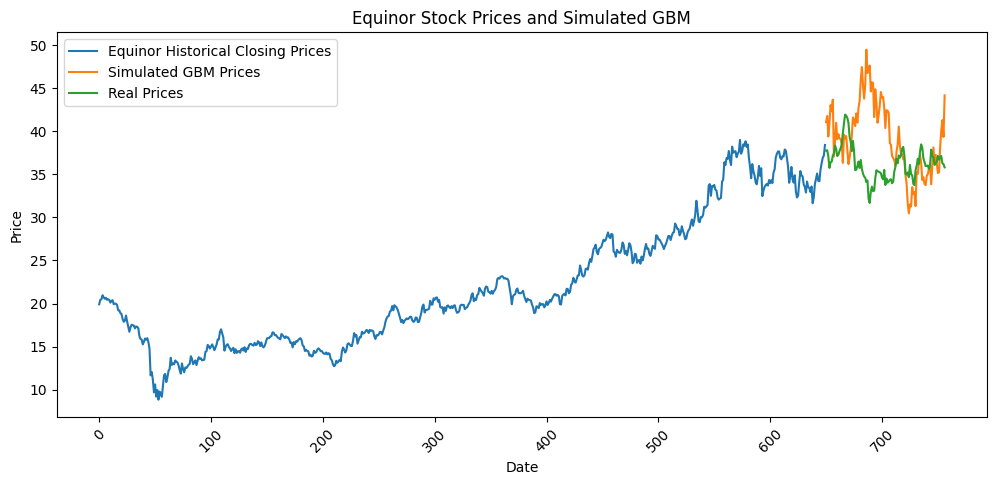

In [22]:
data2 = eqnr[:650]
data3 = eqnr[650:]
test_days = len(data3)

returns = data2['Close'].pct_change()

mu = returns.mean() * 252  # Annualize the mean
sigma = returns.std() * np.sqrt(252)  # Annualize the std deviation

T = 1  # Time horizon in years
dt = 1/test_days  # Time step in years, assuming 252 trading days per year
N = int(T/dt)  # Number of time steps
time_step = np.linspace(0, T, N)
S0 = data2['Close'].iloc[-1]  # Starting stock price (latest close price)

W = np.random.standard_normal(size=N)
W = np.cumsum(W)*np.sqrt(dt)  # Cumulative sum for the Wiener process
X = (mu - 0.5 * sigma**2) * time_step + sigma * W
S = S0 * np.exp(X)  # GBM formula

plt.figure(figsize=(12, 5))
plt.plot(data2['Close'], label='Equinor Historical Closing Prices')
plt.plot(data3.index, S, label='Simulated GBM Prices')
plt.plot(data3['Close'], label='Real Prices')
plt.legend()
plt.title('Equinor Stock Prices and Simulated GBM')
plt.xlabel('Date')
plt.ylabel('Price')
plt.xticks(rotation=45);

In [20]:
n_paths = 10
paths = []
for _ in range(n_paths):
  W = np.cumsum(np.random.standard_normal(size=N))*np.sqrt(dt)
  X = (mu - 0.5 * sigma**2) * time_step + sigma * W
  paths.append(S0 * np.exp(X))

path_mean = np.array(paths).mean(axis=0)
path_std = np.array(paths).std(axis=0)

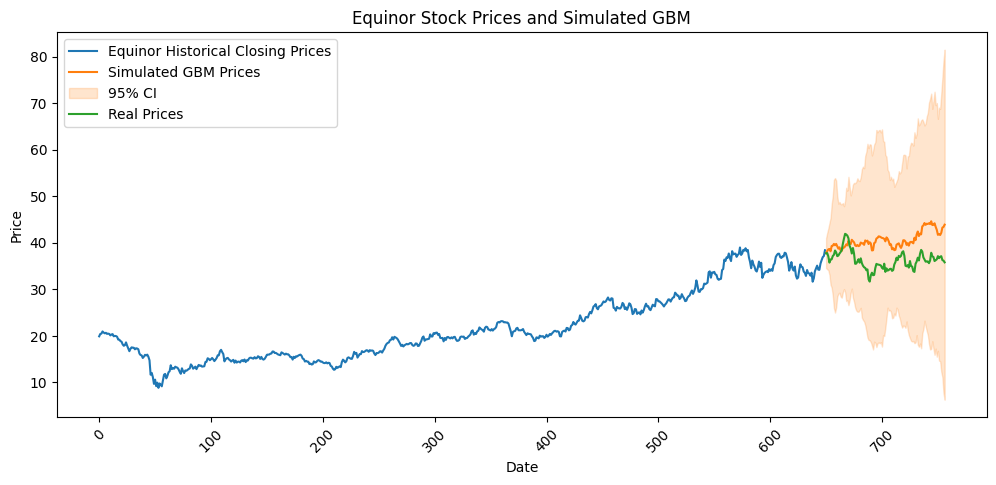

In [23]:
plt.figure(figsize=(12, 5))
plt.plot(data2['Close'], label='Equinor Historical Closing Prices')
plt.plot(data3.index, path_mean, label='Simulated GBM Prices')
plt.fill_between(data3.index, path_mean-1.96*path_std, path_mean+1.96*path_std, color='tab:orange', alpha=0.2, label='95% CI')
plt.plot(data3['Close'], label='Real Prices')
plt.legend(loc='upper left')
plt.title('Equinor Stock Prices and Simulated GBM')
plt.xlabel('Date')
plt.ylabel('Price')
plt.xticks(rotation=45);

Как и было предположено, акции Equinor проще предсказать, чем Tesla. На графике видно, что прогноз и тест немного различаются, но идут в одном направлении.